# OP-FL v2 — 06b. Faisabilité : la calibration d'un hôpital nouveau est-elle prévisible sans ses labels ?

**Constat des notebooks 02 à 05.** Sur des hôpitaux jamais vus, le modèle fédéré garde son classement, mais il se trompe de **niveau de risque**, et l'écart change d'un hôpital à l'autre.
Cet écart est la calibration-in-the-large (CITL). Pour un label défini par un examen (hyperlactatémie), la prévalence enregistrée suit l'intensité de dosage du site, alors que la prévalence chez les patients redosés reste stable.

**Question.** Avant de construire une méthode, on vérifie si le décalage a_h d'un hôpital nouveau est **prévisible** :
1. **sans aucun label** de l'hôpital, à partir de descripteurs du site (régime 0) ;
2. avec le **nombre d'événements** de l'hôpital (régime 1) ou **k labels** (régime 2), en partant d'un a priori appris sur les autres hôpitaux plutôt que de zéro ;
3. pour un label **défini par un examen**, à partir du **taux de dosage** du site. Si Y* = D × Y et que P(Y | D = 1, x) se transporte d'un hôpital à l'autre, alors a_h ≈ log(taux de dosage_h) + constante.

Ce notebook **n'entraîne aucun modèle**. Il réutilise les prédictions de transfert des notebooks 02 et 05 (hôpitaux tenus à l'écart, `val + test`, moyennées sur les seeds complètes).

---

**Cible, par hôpital de développement, une seule fois (dans le pli où il est tenu à l'écart).** a_h est le décalage d'intercept (offset logistique) qui recalibre le score sur ses patients d'évaluation, avec la variance 1 / Σ μ(1 − μ).
C'est une cible **hors fédération** : le modèle évalué n'a jamais vu l'hôpital. Un a_h > 0 signifie que le risque est sous-estimé.

**Descripteurs sans label** (split `train` de l'hôpital, usage prévu par le protocole : « adaptation SANS label ») :

| Groupe | Contenu | Pourquoi |
|---|---|---|
| `obs` | couvertures à 24 h (lactate, gaz du sang, PA invasive, GCS, diurèse, température), variables indisponibles, **part des patients redosés après 24 h** (lactate, créatinine) et intensité de dosage | processus d'observation du site ; le *fait* qu'un examen soit fait, jamais son résultat |
| `case` | âge moyen, part de femmes, types d'unité, provenance (urgences, bloc, étage, transfert), grandes familles de diagnostic d'admission | case-mix |
| `struct` | taille (log du nombre de séjours), catégorie de lits, statut universitaire, région | structure de l'hôpital (table `hospital` d'eICU) |
| `model` | moyenne et écart-type du logit prédit sur les patients d'évaluation | ce que le modèle « voit » du site, sans label |
| `apache` | logit moyen de la prédiction APACHE IVa, part manquante | **secondaire uniquement** : référence clinique, jamais dans `S_all` |
| `mech` | log de la part des patients redosés (lactate ou créatinine) | mécanisme Y* = D × Y |

**Méta-modèle (régime 0).** Méta-régression bayésienne empirique : a_h = μ + z_h'β + u_h + e_h, avec β ~ N(0, s²_β) sur descripteurs standardisés, u_h ~ N(0, τ²) (hétérogénéité non expliquée) et e_h ~ N(0, v_h) (bruit d'estimation de a_h).
(τ², s²_β) sont estimés par maximum de vraisemblance restreinte (REML), sans réglage par validation croisée. Le modèle donne pour un hôpital nouveau un **a priori N(â_h, V_h)** (moyenne et variance prédictive), réutilisé tel quel aux régimes 1 et 2.
Il est **croisé par pli du protocole** : le méta-modèle qui prédit les hôpitaux du pli f est appris sur les a_h des hôpitaux des 4 autres plis. Sensibilité : ridge pondéré avec λ choisi par validation croisée interne.
Comparateurs : `E0` (aucune correction) et `E1` (moyenne des a_h des autres hôpitaux).
`S_mech_fixe` impose a_h = μ + 1 × (log r_h − moyenne) sans rien ajuster ; `S_mech` ajuste le coefficient.

**Régimes 1 et 2 (simulation sur les vrais patients).** Les patients d'évaluation de chaque hôpital sont coupés au hasard en deux moitiés, 50 fois.
La moitié « historique » fournit soit le nombre total d'événements (régime 1), soit k labels (régime 2). La moitié « déploiement » sert à mesurer le |CITL| restant.
Méthodes comparées : décalage local seul, rétrécissement fixe vers la moyenne (a priori N(μ, 1/10)), bayésien empirique avec a priori global N(μ, τ² + var μ), et **bayésien empirique avec a priori des descripteurs** N(â_h, V_h).

**Mesures.** |CITL| résiduel moyen ; R²_τ = 1 − τ²(résidus) / τ²(brut) (DerSimonian-Laird, qui retire le bruit d'échantillonnage) ; IC à 95 % par bootstrap des hôpitaux (2000 tirages).

---

### Critères fixés avant les résultats (étape 7)

| Code | Question | Mesure | Rempli si |
|---|---|---|---|
| **F1** | La calibration d'un hôpital nouveau est-elle prévisible sans label ? | mortalité, `x_only`, `S_all` : R²_τ, et gain moyen \|CITL\|(E1) − \|CITL\|(S_all) | R²_τ ≥ 0,25 **et** borne basse de l'IC du gain > 0 |
| **F2** | Un a priori appris aide-t-il quand on a peu de labels ? | mortalité, `x_only`, k = 50 : \|CITL\| du meilleur comparateur simple (local ou rétrécissement fixe) − \|CITL\| de l'EB avec descripteurs | borne basse de l'IC > 0 |
| **F3** | Le taux de dosage explique-t-il la calibration d'un label défini par un examen ? | hyperlactatémie, `x_only` : R²_τ de `S_mech`, ou corrélation de Spearman entre a_h et log(taux de dosage) | R²_τ ≥ 0,5 **ou** ρ ≥ 0,5 |

Le contraste AKI (créatinine, examen de routine, peu de variation de dosage) est descriptif. Les modèles `x_obs`, `grud` et les autres ensembles de descripteurs sont secondaires.

| Verdict (évalué dans l'ordre) | Condition | Suite |
|---|---|---|
| **GO COMPLET** | F1 et F2 | méthode : a priori hiérarchique de calibration de site (régimes 0 à 2), plus le bras mécanistique si F3 |
| **GO RÉGIME 0** | F1 | méthode centrée sur la calibration sans label ; le gain disparaît avec quelques labels |
| **GO LABELS OBSERVÉS** | F3 et F2 | méthode centrée sur les labels définis par un examen (transport factorisé) + EB peu de labels |
| **GO MÉCANISME** | F3 | méthode centrée sur les labels définis par un examen (transport factorisé) |
| **GO PEU DE LABELS** | F2 | méthode bayésienne empirique peu de labels, sans prédiction a priori |
| **NO-GO** | sinon | la calibration de site n'est pas prévisible ici : ne pas en faire la contribution |

**Garde-fous.** Test verrouillé jamais chargé. Aucun descripteur ne lit un résultat d'examen ni un devenir (contrôle par permutation des labels, étape 8). APACHE IVa n'entre jamais dans `S_all`. Seuls des agrégats sortent de ce notebook : le rapport ne contient ni donnée patient ni identifiant d'hôpital.
**Limites connues.** 60 hôpitaux (48 pour apprendre chaque méta-modèle) : R²_τ est imprécis, d'où les IC. Pour le lactate, environ 5 événements par hôpital tenu à l'écart : a_h est bruité, R²_τ corrige ce bruit mais pas la corrélation de Spearman.

## Étape 0 — Configuration et critères

Les tâches dont les prédictions manquent sont ignorées avec un message, sauf la tâche principale (mortalité, `x_only`, notebook 02).

In [11]:
# ============================================================
# ÉTAPE 0 — CONFIGURATION ET CRITÈRES (FIXÉS AVANT LES RÉSULTATS)
# ============================================================
import sys, json, importlib, warnings
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)

PROJECT_DIR = Path("..")
DATA_DIR = PROJECT_DIR / "data_v1"
SRC_DIR = PROJECT_DIR / "src"
RES02 = PROJECT_DIR / "results" / "02_baselines"
RES04 = PROJECT_DIR / "results" / "04_observation_label"
RES05 = PROJECT_DIR / "results" / "05_raccourci_masquage"
RES_DIR = PROJECT_DIR / "results" / "06b_faisabilite_opcal"
FIG_DIR = RES_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR.resolve()))

EXPECTED_PROTOCOL_HASH = "d92099ea7c11d517"
protocol = json.loads((DATA_DIR / "splits" / "protocol.json").read_text(encoding="utf-8"))
assert protocol["hash"] == EXPECTED_PROTOCOL_HASH, f"Protocole inattendu ({protocol['hash']})."
FOLDS = sorted(int(k) for k in protocol["folds"])
FOLD_OF = {int(h): int(k) for k in protocol["folds"] for h in protocol["folds"][k]}
DEV = sorted(FOLD_OF)
LOCKED = set(int(h) for h in protocol["locked_test_hospitals"])
assert LOCKED.isdisjoint(DEV)
STAY_LABELS = RES04 / "stay_labels.parquet"
assert STAY_LABELS.exists(), "Exécuter d'abord le notebook 04 (étapes 0 à 3)."
cfg04 = json.loads((RES04 / "config.json").read_text(encoding="utf-8"))
assert cfg04["protocol_hash"] == protocol["hash"]

TASKS = {
    "mortalite_x_only": {"pred_dir": RES02 / "preds", "name": "x_only", "label": "y_mortality", "pop": "tous", "role": "principal"},
    "mortalite_x_obs":  {"pred_dir": RES02 / "preds", "name": "x_obs", "label": "y_mortality", "pop": "tous", "role": "secondaire"},
    "mortalite_grud":   {"pred_dir": RES02 / "preds", "name": "grud", "label": "y_mortality", "pop": "tous", "role": "secondaire"},
    "lactate_x_only":   {"pred_dir": RES05 / "preds", "name": "A_lac_neg_x_only", "label": "hyper_neg", "pop": "present48",
                         "role": "mécanisme", "mech": "test_rate_lactate"},
    "lactate_x_obs":    {"pred_dir": RES05 / "preds", "name": "A_lac_neg_x_obs", "label": "hyper_neg", "pop": "present48",
                         "role": "secondaire", "mech": "test_rate_lactate"},
    "aki_x_only":       {"pred_dir": RES05 / "preds", "name": "A_aki_neg_x_only", "label": "aki_neg", "pop": "present48_crbase",
                         "role": "contraste", "mech": "test_rate_creatinine"},
    "aki_x_obs":        {"pred_dir": RES05 / "preds", "name": "A_aki_neg_x_obs", "label": "aki_neg", "pop": "present48_crbase",
                         "role": "secondaire", "mech": "test_rate_creatinine"},
}
PRIMARY, MECH_TASK, CONTRAST_TASK = "mortalite_x_only", "lactate_x_only", "aki_x_only"

# ensembles de descripteurs : None = aucune correction ; [] = moyenne globale ; ("fixe",) = mécanisme sans ajustement
SETS = {"E0_aucune": None, "E1_moyenne": [], "S_obs": ["obs"], "S_case": ["case"], "S_struct": ["struct"],
        "S_model": ["model"], "S_all": ["obs", "case", "struct", "model"]}
SETS_MORT = {**SETS, "S_all+apache": ["obs", "case", "struct", "model", "apache"]}
SETS_MECH = {**SETS, "S_mech_fixe": ("fixe",), "S_mech": ["mech"]}

CRIT = {"F1_R2tau": 0.25, "F2_k": 50, "F3_R2tau": 0.5, "F3_rho": 0.5}
K_GRID = [25, 50, 100, 200]
N_REP, N0_FIXED = 50, 10.0
N_BOOT, SEED = 2000, 2026
(RES_DIR / "config.json").write_text(json.dumps(
    {"protocol_hash": protocol["hash"], "tasks": {t: {k: str(v) for k, v in c.items()} for t, c in TASKS.items()},
     "sets": {k: v for k, v in SETS_MECH.items()} | {"S_all+apache": SETS_MORT["S_all+apache"]},
     "criteria": CRIT, "k_grid": K_GRID, "n_rep": N_REP, "n0_fixed": N0_FIXED, "n_boot": N_BOOT, "seed": SEED,
     "created_at": datetime.now().isoformat(timespec="seconds")}, indent=2, default=str), encoding="utf-8")
print(f"Protocole {protocol['hash']} | {len(DEV)} hôpitaux de développement, {len(FOLDS)} plis | test verrouillé : {len(LOCKED)} hôpitaux (jamais chargés)")
print("Critères :", CRIT)

Protocole d92099ea7c11d517 | 60 hôpitaux de développement, 5 plis | test verrouillé : 96 hôpitaux (jamais chargés)
Critères : {'F1_R2tau': 0.25, 'F2_k': 50, 'F3_R2tau': 0.5, 'F3_rho': 0.5}


## Étape 1 — Module `src/opcal_feas.py`

Calibration par hôpital (offset logistique), méta-analyse DerSimonian-Laird, descripteurs sans label, méta-régression REML (`SiteEB`) croisée par pli, simulation des régimes 1 et 2, mécanisme Y* = D × Y.

In [12]:
# %%writefile ../src/opcal_feas.py
# """
# opcal_feas — faisabilité de la calibration de site pour des hôpitaux nouveaux (OP-Cal).

# Généré par notebooks/06b_faisabilite_opcal.ipynb (étape 1) : modifier le notebook, pas ce fichier.

# Idée : un modèle fédéré transporté vers un hôpital h garde son classement mais se trompe surtout de
# niveau de risque, d'une quantité a_h (calibration-in-the-large, log-odds). On teste si a_h est :
#   - prévisible SANS label à partir de descripteurs du site (régime 0) ;
#   - mieux estimé avec un taux agrégé (régime 1) ou k labels (régime 2) quand on part d'un a priori
#     appris sur les autres hôpitaux (bayésien empirique) plutôt que de zéro ;
#   - pour un label défini par un examen (lactate, créatinine), expliqué par le taux de dosage du site.

# Aucune fonction ne lit un label pour construire un descripteur : les descripteurs utilisent les
# entrées (couvertures, case-mix, structure, prédictions du modèle) et le fait qu'un examen ait été fait,
# jamais son résultat ni le devenir du patient.
# """
# import json
# import re
# from pathlib import Path

# import numpy as np
# import pandas as pd

# # ----------------------------------------------------------------------------------------------
# # Outils numériques
# # ----------------------------------------------------------------------------------------------

# def sigmoid(z):
#     return 1.0 / (1.0 + np.exp(-np.clip(z, -35, 35)))


# def logit(p, eps=1e-6):
#     p = np.clip(np.asarray(p, float), eps, 1 - eps)
#     return np.log(p / (1 - p))


# def offset_fit(lp, y=None, total=None, prior_mean=0.0, prior_var=np.inf, max_iter=100):
#     """Décalage a (log-odds) à ajouter à lp. Données : labels individuels y, OU nombre total
#     d'événements `total` (régime 1). Prior gaussien optionnel N(prior_mean, prior_var).
#     Sans prior : correction de continuité (cible bornée à [0,5 ; n - 0,5]), comme site_offset.
#     Retourne (a, variance a posteriori)."""
#     lp = np.asarray(lp, float)
#     n = len(lp)
#     s = float(np.sum(y)) if y is not None else float(total)
#     prec0 = 0.0 if not np.isfinite(prior_var) else 1.0 / max(prior_var, 1e-9)
#     if prec0 == 0.0:
#         s = float(np.clip(s, 0.5, n - 0.5))
#     a = float(prior_mean) if prec0 > 0 else 0.0
#     for _ in range(max_iter):
#         mu = sigmoid(lp + a)
#         g = s - mu.sum() - prec0 * (a - prior_mean)
#         h = (mu * (1 - mu)).sum() + prec0
#         step = float(np.clip(g / max(h, 1e-9), -5, 5))
#         a += step
#         if abs(step) < 1e-10:
#             break
#     mu = sigmoid(lp + a)
#     return float(a), float(1.0 / max((mu * (1 - mu)).sum() + prec0, 1e-9))


# def citl(lp, y):
#     """Calibration-in-the-large : décalage qui recalibre lp sur y (> 0 = risque sous-estimé)."""
#     return offset_fit(lp, y)


# def cal_slope(lp, y, max_iter=50):
#     lp, y = np.asarray(lp, float), np.asarray(y, float)
#     if y.sum() < 2 or y.sum() > len(y) - 2:
#         return np.nan, np.nan
#     X = np.column_stack([np.ones(len(lp)), lp])
#     b = np.array([0.0, 1.0])
#     for _ in range(max_iter):
#         mu = sigmoid(X @ b)
#         H = (X * (mu * (1 - mu))[:, None]).T @ X + 1e-9 * np.eye(2)
#         step = np.linalg.solve(H, X.T @ (y - mu))
#         b += np.clip(step, -5, 5)
#         if np.max(np.abs(step)) < 1e-9:
#             break
#     mu = sigmoid(X @ b)
#     H = (X * (mu * (1 - mu))[:, None]).T @ X
#     try:
#         se = float(np.sqrt(np.linalg.inv(H)[1, 1]))
#     except np.linalg.LinAlgError:
#         se = np.nan
#     return float(b[1]), se


# def random_effects(beta, var):
#     """Méta-analyse DerSimonian-Laird : mu, tau2, I2, Q, p(Q)."""
#     from scipy import stats
#     beta, var = np.asarray(beta, float), np.asarray(var, float)
#     ok = np.isfinite(beta) & np.isfinite(var) & (var > 0)
#     beta, var = beta[ok], var[ok]
#     k = len(beta)
#     if k < 3:
#         return {"k": k, "mu": np.nan, "tau2": np.nan, "tau": np.nan, "I2": np.nan, "Q": np.nan, "Q_p": np.nan}
#     w = 1 / var
#     mu_fe = np.sum(w * beta) / np.sum(w)
#     Q = float(np.sum(w * (beta - mu_fe) ** 2))
#     C = np.sum(w) - np.sum(w ** 2) / np.sum(w)
#     tau2 = max(0.0, (Q - (k - 1)) / C)
#     ws = 1 / (var + tau2)
#     return {"k": k, "mu": float(np.sum(ws * beta) / np.sum(ws)), "tau2": float(tau2),
#             "tau": float(np.sqrt(tau2)), "I2": float(max(0.0, (Q - (k - 1)) / Q)) if Q > 0 else 0.0,
#             "Q": Q, "Q_p": float(stats.chi2.sf(Q, k - 1))}


# def boot_mean_diff(a, b, n_boot=2000, seed=0):
#     """Moyenne de (a - b) sur les hôpitaux et IC 95 % par bootstrap des hôpitaux."""
#     a, b = np.asarray(a, float), np.asarray(b, float)
#     ok = np.isfinite(a) & np.isfinite(b)
#     d = a[ok] - b[ok]
#     rng = np.random.default_rng(seed)
#     bs = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n_boot)])
#     return float(d.mean()), float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))


# # ----------------------------------------------------------------------------------------------
# # Chargement des prédictions de transfert (notebooks 02 et 05)
# # ----------------------------------------------------------------------------------------------

# _PAT = re.compile(r"^(?P<name>.+)__fold(?P<fold>\d+)__seed(?P<seed>\d+)\.parquet$")


# def list_runs(pred_dir):
#     rows = []
#     for p in Path(pred_dir).glob("*.parquet"):
#         m = _PAT.match(p.name)
#         if m:
#             rows.append({"name": m["name"], "fold": int(m["fold"]), "seed": int(m["seed"]), "path": p})
#     return pd.DataFrame(rows, columns=["name", "fold", "seed", "path"])


# def load_transfer(pred_dir, name, folds):
#     """Prédictions 'transfer' d'une configuration, moyennées sur les seeds disponibles pour TOUS les plis."""
#     runs = list_runs(pred_dir)
#     r = runs[runs["name"] == name]
#     if r.empty:
#         raise FileNotFoundError(f"Aucune prédiction pour '{name}' dans {pred_dir}")
#     seeds = [s for s in sorted(r["seed"].unique()) if set(r.loc[r["seed"] == s, "fold"]) >= set(folds)]
#     if not seeds:
#         raise RuntimeError(f"'{name}' : aucune seed complète sur les plis {folds}")
#     parts = []
#     for _, row in r[r["seed"].isin(seeds) & r["fold"].isin(folds)].iterrows():
#         d = pd.read_parquet(row["path"])
#         d = d[d["role"] == "transfer"]
#         cols = ["stay_id", "hospitalid", "p"] + (["y"] if "y" in d.columns else [])
#         parts.append(d[cols].assign(fold=row["fold"], seed=row["seed"]))
#     d = pd.concat(parts, ignore_index=True)
#     agg = {"hospitalid": ("hospitalid", "first"), "fold": ("fold", "first"), "p": ("p", "mean"),
#            "n_seeds": ("seed", "nunique")}
#     if "y" in d.columns:
#         agg["y"] = ("y", "first")
#     out = d.groupby("stay_id").agg(**agg).reset_index()
#     out["lp"] = logit(out["p"].to_numpy())
#     return out, seeds


# # ----------------------------------------------------------------------------------------------
# # Calibration par hôpital tenu à l'écart
# # ----------------------------------------------------------------------------------------------

# def hospital_calibration(df):
#     """df : stay_id, hospitalid, fold, lp, y. Une ligne par hôpital."""
#     rows = []
#     for h, g in df.groupby("hospitalid"):
#         lp, y = g["lp"].to_numpy(), g["y"].to_numpy(float)
#         a, v = citl(lp, y)
#         b, se_b = cal_slope(lp, y)
#         rows.append({"hospitalid": int(h), "fold": int(g["fold"].iloc[0]), "n": len(g), "events": int(y.sum()),
#                      "prevalence": float(y.mean()), "mean_lp": float(lp.mean()), "sd_lp": float(lp.std()),
#                      "citl": a, "var_citl": v, "slope": b, "se_slope": se_b})
#     return pd.DataFrame(rows).set_index("hospitalid").sort_index()


# # ----------------------------------------------------------------------------------------------
# # Descripteurs de site, sans label
# # ----------------------------------------------------------------------------------------------

# BLOODGAS = ["lactate", "pH", "paO2", "paCO2", "FiO2"]
# OBS_COV = {"cov_lactate": ["lactate"], "cov_bloodgas": BLOODGAS, "cov_invasive_bp": ["systemicmean"],
#            "cov_gcs": ["GCS Total"], "cov_urine": ["urine_output"], "cov_temperature": ["temperature"]}
# DX_KEYS = {"dx_sepsis": r"sepsis", "dx_cardiac_surgery": r"cabg|valve", "dx_arrest": r"cardiac arrest",
#            "dx_overdose": r"overdose", "dx_stroke": r"cva|stroke", "dx_chf": r"chf|congestive",
#            "dx_ami": r"infarction, acute myocardial", "dx_respiratory": r"pneumonia|emphysema|copd|asthma",
#            "dx_gi_bleed": r"bleed", "dx_dka": r"ketoacidosis"}
# SRC_GROUPS = {"Emergency Department": "src_ed", "Operating Room": "src_or", "Recovery Room": "src_or",
#               "PACU": "src_or", "Floor": "src_floor", "Step-Down Unit (SDU)": "src_floor",
#               "ICU to SDU": "src_floor", "Acute Care/Floor": "src_floor", "Other Hospital": "src_transfer",
#               "Direct Admit": "src_direct"}
# BEDS = {"<100": 0, "100 - 249": 1, "100-249": 1, "250 - 499": 2, "250-499": 2, ">= 500": 3, ">=500": 3}


# def site_descriptors(data_dir, stay_labels_path, hospitals):
#     """Descripteurs sans label par hôpital (split train uniquement pour tout ce qui est patient).
#     Retourne (DataFrame indexé par hospitalid, dict groupe -> colonnes)."""
#     data_dir = Path(data_dir)
#     feats = json.loads((data_dir / "features.json").read_text(encoding="utf-8"))["features"]
#     local = json.loads((data_dir / "normalizers" / "local_stats.json").read_text(encoding="utf-8"))
#     manifest = pd.read_csv(data_dir / "clients" / "manifest.csv").set_index("hospitalid")
#     splits = pd.read_parquet(data_dir / "splits" / "patient_splits.parquet")[["patientunitstayid", "split"]]
#     cols_c = ["patientunitstayid", "hospitalid", "age_num", "gender", "apacheadmissiondx", "unittype",
#               "unitadmitsource"]
#     coh = pd.read_parquet(data_dir / "interim" / "cohort_final.parquet", columns=cols_c)
#     coh = coh.merge(splits, on="patientunitstayid")
#     coh = coh[(coh["split"] == "train") & coh["hospitalid"].isin(hospitals)]
#     D = pd.DataFrame(index=pd.Index(sorted(int(h) for h in hospitals), name="hospitalid"))
#     groups = {}

#     # --- processus d'observation (24 h) : couvertures et disponibilité (local_stats, split train)
#     idx = {f: i for i, f in enumerate(feats)}
#     for name, vs in OBS_COV.items():
#         ii = [idx[v] for v in vs if v in idx]
#         D[name] = [float(np.mean([local[str(h)]["coverage"][i] for i in ii])) if ii else np.nan for h in D.index]
#     D["n_unavailable"] = [int(np.sum(np.asarray(local[str(h)]["avail"]) == 0)) for h in D.index]
#     D["mean_coverage"] = [float(np.mean(local[str(h)]["coverage"])) for h in D.index]
#     obs_cols = list(OBS_COV) + ["n_unavailable", "mean_coverage"]

#     # --- processus d'observation après 24 h : un examen a-t-il été refait ? (jamais son résultat)
#     if stay_labels_path is not None and Path(stay_labels_path).exists():
#         st = pd.read_parquet(stay_labels_path)
#         st = st[(st["split"] == "train") & st["present48"].astype(bool) & st["hospitalid"].isin(hospitals)]
#         g = st.groupby("hospitalid")
#         D["test_rate_lactate"] = g["obs_la"].mean().reindex(D.index)
#         D["test_rate_creatinine"] = st[st["cr_base"].notna()].groupby("hospitalid")["obs_cr"].mean().reindex(D.index)
#         D["intensity_lactate"] = g["la_rate"].mean().reindex(D.index)
#         D["intensity_creatinine"] = g["cr_rate"].mean().reindex(D.index)
#         obs_cols += ["test_rate_lactate", "test_rate_creatinine", "intensity_lactate", "intensity_creatinine"]
#     groups["obs"] = obs_cols

#     # --- case-mix (split train)
#     g = coh.groupby("hospitalid")
#     D["age_mean"] = g["age_num"].mean().reindex(D.index)
#     D["female_share"] = coh.assign(f=(coh["gender"] == "Female").astype(float)).groupby("hospitalid")["f"].mean().reindex(D.index)
#     top_units = coh["unittype"].value_counts().index[:6]
#     case_cols = ["age_mean", "female_share"]
#     for u in top_units:
#         c = "unit_" + re.sub(r"[^0-9a-z]+", "_", str(u).lower()).strip("_")
#         D[c] = coh.assign(f=(coh["unittype"] == u).astype(float)).groupby("hospitalid")["f"].mean().reindex(D.index)
#         case_cols.append(c)
#     src = coh["unitadmitsource"].map(SRC_GROUPS).fillna("src_other")
#     for s in ["src_ed", "src_or", "src_floor", "src_transfer", "src_direct"]:
#         D[s] = coh.assign(f=(src == s).astype(float)).groupby("hospitalid")["f"].mean().reindex(D.index)
#         case_cols.append(s)
#     dx = coh["apacheadmissiondx"].fillna("").astype(str).str.lower()
#     for c, pat in DX_KEYS.items():
#         D[c] = coh.assign(f=dx.str.contains(pat, regex=True).astype(float)).groupby("hospitalid")["f"].mean().reindex(D.index)
#         case_cols.append(c)
#     groups["case"] = case_cols

#     # --- structure de l'hôpital (table hospital d'eICU, fusionnée dans hospital_quality.csv)
#     struct_cols = ["log_size"]
#     D["log_size"] = np.log(manifest.loc[D.index, "n_stays"].astype(float))
#     qp = data_dir / "reports" / "hospital_quality.csv"
#     if qp.exists():
#         q = pd.read_csv(qp).drop_duplicates("hospitalid").set_index("hospitalid").reindex(D.index)
#         if "numbedscategory" in q:
#             D["beds_cat"] = q["numbedscategory"].astype(str).str.strip().map(BEDS)
#             struct_cols.append("beds_cat")
#         if "teachingstatus" in q:
#             D["teaching"] = q["teachingstatus"].astype(str).str.lower().isin(["t", "true", "1", "yes"]).astype(float)
#             struct_cols.append("teaching")
#         if "region" in q:
#             for r in ["Midwest", "Northeast", "South", "West"]:
#                 D[f"region_{r.lower()}"] = (q["region"].astype(str) == r).astype(float)
#                 struct_cols.append(f"region_{r.lower()}")
#             D["region_missing"] = q["region"].isna().astype(float)
#             struct_cols.append("region_missing")
#     groups["struct"] = struct_cols

#     # --- score de référence APACHE IVa (moyenne du site, split train) : descripteur secondaire
#     ap = {}
#     for h in D.index:
#         z = np.load(data_dir / "clients" / f"hospital_{h}.npz")
#         a = z["apache_pred"][z["split"] == 0]
#         a = a[np.isfinite(a)]
#         ap[h] = (float(logit(np.clip(a.mean(), 1e-4, 1 - 1e-4))) if len(a) else np.nan,
#                  float(1 - len(a) / max((z["split"] == 0).sum(), 1)))
#     D["apache_logit_mean"] = [ap[h][0] for h in D.index]
#     D["apache_missing_share"] = [ap[h][1] for h in D.index]
#     groups["apache"] = ["apache_logit_mean", "apache_missing_share"]
#     return D, groups


# # ----------------------------------------------------------------------------------------------
# # Méta-modèle de la calibration de site (régime 0), croisé par pli
# # ----------------------------------------------------------------------------------------------

# class SiteRidge:
#     """Régression ridge pondérée de a_h sur des descripteurs standardisés ; intercept non pénalisé."""

#     def __init__(self, lam):
#         self.lam = lam

#     def fit(self, Z, c, w):
#         Z = np.asarray(Z, float)
#         self.fill = np.nanmean(Z, axis=0) if Z.shape[1] else np.zeros(0)
#         self.fill = np.where(np.isfinite(self.fill), self.fill, 0.0)
#         Z = np.where(np.isfinite(Z), Z, self.fill)
#         w = np.asarray(w, float) / np.sum(w)
#         self.mz = (w[:, None] * Z).sum(0)
#         sd = np.sqrt((w[:, None] * (Z - self.mz) ** 2).sum(0))
#         self.sz = np.where(sd > 1e-9, sd, 1.0)
#         Zs = (Z - self.mz) / self.sz
#         cbar = float(np.sum(w * c))
#         if Zs.shape[1]:
#             A = (Zs * w[:, None]).T @ Zs + self.lam * np.eye(Zs.shape[1]) / len(c)
#             self.beta = np.linalg.solve(A, (Zs * w[:, None]).T @ (c - cbar))
#         else:
#             self.beta = np.zeros(0)
#         self.b0 = cbar
#         return self

#     def predict(self, Z):
#         Z = np.asarray(Z, float)
#         Z = np.where(np.isfinite(Z), Z, self.fill)
#         return self.b0 + ((Z - self.mz) / self.sz) @ self.beta


# LAM_GRID = [0.3, 1, 3, 10, 30, 100, 300, 1000]


# class SiteEB:
#     """Méta-régression bayésienne empirique de la calibration de site :
#         a_h = mu + z_h' beta + u_h + e_h,  beta ~ N(0, s2b I) (descripteurs standardisés),
#         u_h ~ N(0, tau2) (hétérogénéité non expliquée),  e_h ~ N(0, v_h) (bruit d'estimation de a_h).
#     (tau2, s2b) par maximum de vraisemblance restreinte (REML) ; aucun réglage par validation croisée.
#     predict() renvoie la moyenne et la variance prédictive d'un hôpital nouveau : c'est l'a priori
#     N(â_h, V_h) utilisé ensuite avec 0, un agrégat ou k labels."""

#     def fit(self, Z, c, v):
#         from scipy.optimize import minimize
#         Z = np.asarray(Z, float).reshape(len(c), -1)
#         c, v = np.asarray(c, float), np.asarray(v, float)
#         self.p = Z.shape[1]
#         if self.p:
#             with np.errstate(all="ignore"):
#                 fill = np.nanmean(Z, axis=0)
#             self.fill = np.where(np.isfinite(fill), fill, 0.0)
#             Z = np.where(np.isfinite(Z), Z, self.fill)
#             self.mz, sd = Z.mean(0), Z.std(0)
#             self.sz = np.where(sd > 1e-9, sd, np.inf)
#             Zs = (Z - self.mz) / self.sz
#         else:
#             Zs = np.zeros((len(c), 0))
#         K = Zs @ Zs.T
#         one = np.ones(len(c))

#         def parts(theta):
#             t2 = np.exp(theta[0])
#             s2 = np.exp(theta[1]) if self.p else 0.0
#             V = s2 * K + np.diag(t2 + v)
#             L = np.linalg.cholesky(V)
#             Vi = np.linalg.solve(L.T, np.linalg.solve(L, np.eye(len(c))))
#             a = one @ Vi @ one
#             mu = (one @ Vi @ c) / a
#             r = c - mu
#             return t2, s2, Vi, a, mu, r, 2 * np.log(np.diag(L)).sum()

#         def nll(theta):
#             try:
#                 t2, s2, Vi, a, mu, r, logdet = parts(theta)
#             except np.linalg.LinAlgError:
#                 return 1e12
#             return 0.5 * (logdet + np.log(a) + r @ Vi @ r)

#         g_t = np.log(np.geomspace(1e-4, 2.0, 12))
#         g_s = np.log(np.geomspace(1e-5, 1.0, 12)) if self.p else [0.0]
#         best = min(((nll([a_, b_]), a_, b_) for a_ in g_t for b_ in g_s))
#         bounds = [(np.log(1e-6), np.log(5.0)), (np.log(1e-7), np.log(2.0))] if self.p else [(np.log(1e-6), np.log(5.0))]
#         x0 = [best[1], best[2]] if self.p else [best[1]]
#         res = minimize(lambda th: nll(th if self.p else [th[0], 0.0]), x0, method="L-BFGS-B", bounds=bounds)
#         theta = res.x if res.fun <= best[0] else np.array(x0)
#         theta = theta if self.p else np.array([theta[0], 0.0])
#         self.tau2, self.s2b, self.Vi, self.a, self.mu, r, _ = parts(theta)
#         self.Zs = Zs
#         self.beta = self.s2b * Zs.T @ (self.Vi @ r) if self.p else np.zeros(0)
#         return self

#     def _std(self, Z):
#         Z = np.asarray(Z, float).reshape(-1, self.p) if self.p else np.zeros((np.asarray(Z).shape[0], 0))
#         if self.p:
#             Z = np.where(np.isfinite(Z), Z, self.fill)
#             Z = (Z - self.mz) / self.sz
#         return Z

#     def predict(self, Z):
#         Zn = self._std(Z)
#         mean = self.mu + Zn @ self.beta
#         var = np.full(len(Zn), self.tau2 + 1.0 / self.a)
#         if self.p:
#             k = self.s2b * Zn @ self.Zs.T
#             var += self.s2b * (Zn ** 2).sum(1) - np.einsum("ij,jk,ik->i", k, self.Vi, k)
#         return mean, np.maximum(var, 1e-6)


# def crossfit_prior(cal, D, cols, fixed_beta=None, engine="eb", lam_grid=LAM_GRID):
#     """Pour chaque pli f : méta-modèle appris sur les a_h (hors fédération) des hôpitaux des AUTRES plis,
#     puis prédiction pour les hôpitaux du pli f, qui n'ont servi à rien d'autre.
#     engine = "eb" (méta-régression REML, principal) ou "ridge" (ridge pondéré, lambda par validation
#     croisée interne, sensibilité). fixed_beta = (colonne, coefficient) : prédicteur mécanistique sans
#     coefficient ajusté (seuls la moyenne et tau2 sont appris).
#     Retourne : a_hat, pred_var (variance prédictive de l'a priori), tau2_raw (DL, autres plis),
#     tau2_resid, hyper (s2b ou lambda), mu."""
#     out = []
#     for f in sorted(cal["fold"].unique()):
#         tr, te = cal[cal["fold"] != f], cal[cal["fold"] == f]
#         c_tr, v_tr = tr["citl"].to_numpy(), tr["var_citl"].to_numpy()
#         tau2_dl = random_effects(c_tr, v_tr)["tau2"]
#         if fixed_beta is not None:
#             col, coef = fixed_beta
#             z_tr, z_te = D.loc[tr.index, col].to_numpy(float), D.loc[te.index, col].to_numpy(float)
#             zbar = float(np.nanmean(z_tr))
#             off_tr = coef * (np.nan_to_num(z_tr, nan=zbar) - zbar)
#             off_te = coef * (np.nan_to_num(z_te, nan=zbar) - zbar)
#             m = SiteEB().fit(np.zeros((len(tr), 0)), c_tr - off_tr, v_tr)
#             mean, var = m.predict(np.zeros((len(te), 0)))
#             mean = mean + off_te
#             res = {"tau2_resid": m.tau2, "hyper": np.nan, "mu": m.mu}
#         elif engine == "eb" or not cols:
#             m = SiteEB().fit(D.loc[tr.index, cols].to_numpy(float), c_tr, v_tr)
#             mean, var = m.predict(D.loc[te.index, cols].to_numpy(float))
#             res = {"tau2_resid": m.tau2, "hyper": m.s2b if cols else np.nan, "mu": m.mu}
#         else:
#             w = 1.0 / (v_tr + tau2_dl)
#             Ztr = D.loc[tr.index, cols].to_numpy(float)
#             inner = tr["fold"].to_numpy()
#             best, lam, best_pred = np.inf, lam_grid[0], None
#             for l_ in lam_grid:
#                 pred_in = np.zeros(len(tr))
#                 for g in np.unique(inner):
#                     a_, b_ = inner != g, inner == g
#                     pred_in[b_] = SiteRidge(l_).fit(Ztr[a_], c_tr[a_], w[a_]).predict(Ztr[b_])
#                 sse = float(np.sum(w * (c_tr - pred_in) ** 2))
#                 if sse < best:
#                     best, lam, best_pred = sse, l_, pred_in.copy()
#             m = SiteRidge(lam).fit(Ztr, c_tr, w)
#             mean = m.predict(D.loc[te.index, cols].to_numpy(float))
#             t2r = random_effects(c_tr - best_pred, v_tr)["tau2"]
#             var = np.full(len(te), t2r)
#             res = {"tau2_resid": t2r, "hyper": lam, "mu": m.b0}
#         out.append(pd.DataFrame({"a_hat": mean, "pred_var": var, "tau2_raw": tau2_dl, **res}, index=te.index))
#     return pd.concat(out).sort_index()


# def evaluate_prior(cal, prior):
#     """Résidus de calibration après correction a_hat, hôpitaux tenus à l'écart."""
#     c, v = cal["citl"], cal["var_citl"]
#     r = c - prior["a_hat"].reindex(c.index)
#     raw, res = random_effects(c, v), random_effects(r, v)
#     return {"mean_abs_citl": float(r.abs().mean()), "median_abs_citl": float(r.abs().median()),
#             "mean_resid": float(r.mean()), "share_abs_lt_0.2": float((r.abs() < 0.2).mean()),
#             "tau2_raw": raw["tau2"], "tau2_resid": res["tau2"],
#             "R2_tau": float(1 - res["tau2"] / raw["tau2"]) if raw["tau2"] > 0 else np.nan}


# # ----------------------------------------------------------------------------------------------
# # Régimes 1 et 2 : taux agrégé ou k labels, avec ou sans a priori appris
# # ----------------------------------------------------------------------------------------------

# def simulate_regimes(stays, prior_desc, prior_glob, k_grid, n_rep=50, n0=10.0, seed=0):
#     """stays : stay_id, hospitalid, lp, y (patients d'évaluation des hôpitaux tenus à l'écart).
#     Chaque répétition coupe les patients d'un hôpital en deux : « historique » (agrégé ou k labels)
#     et « déploiement » (évaluation). Retourne le |CITL| sur la moitié déploiement après correction."""
#     rng = np.random.default_rng(seed)
#     rows = []
#     for h, g in stays.groupby("hospitalid"):
#         lp_all, y_all = g["lp"].to_numpy(), g["y"].to_numpy(float)
#         pd_, pg = prior_desc.loc[h], prior_glob.loc[h]
#         for rep in range(n_rep):
#             perm = rng.permutation(len(g))
#             half = len(g) // 2
#             H, Dp = perm[:half], perm[half:]
#             lpD, yD = lp_all[Dp], y_all[Dp]

#             def resid(a):
#                 return abs(offset_fit(lpD + a, yD)[0])

#             base = {"hospitalid": h, "rep": rep}
#             rows.append({**base, "k": 0, "method": "aucune", "abs_citl": resid(0.0)})
#             rows.append({**base, "k": 0, "method": "moyenne", "abs_citl": resid(pg["a_hat"])})
#             rows.append({**base, "k": 0, "method": "descripteurs", "abs_citl": resid(pd_["a_hat"])})
#             tot = y_all[H].sum()
#             rows.append({**base, "k": -1, "method": "agrege_local",
#                          "abs_citl": resid(offset_fit(lp_all[H], total=tot)[0])})
#             rows.append({**base, "k": -1, "method": "agrege_EB_descripteurs",
#                          "abs_citl": resid(offset_fit(lp_all[H], total=tot, prior_mean=pd_["a_hat"],
#                                                       prior_var=pd_["pred_var"])[0])})
#             for k in k_grid:
#                 if k > len(H):
#                     continue
#                 L = H[:k]
#                 lpL, yL = lp_all[L], y_all[L]
#                 rows += [
#                     {**base, "k": k, "method": "local", "abs_citl": resid(offset_fit(lpL, yL)[0])},
#                     {**base, "k": k, "method": "retrecissement_fixe",
#                      "abs_citl": resid(offset_fit(lpL, yL, prior_mean=pg["a_hat"], prior_var=1.0 / n0)[0])},
#                     {**base, "k": k, "method": "EB_global",
#                      "abs_citl": resid(offset_fit(lpL, yL, prior_mean=pg["a_hat"], prior_var=pg["pred_var"])[0])},
#                     {**base, "k": k, "method": "EB_descripteurs",
#                      "abs_citl": resid(offset_fit(lpL, yL, prior_mean=pd_["a_hat"], prior_var=pd_["pred_var"])[0])},
#                 ]
#     return pd.DataFrame(rows)


# def summarize_regimes(sim):
#     """|CITL| moyen par (k, méthode) : moyenne sur les répétitions par hôpital, puis sur les hôpitaux."""
#     per_h = sim.groupby(["k", "method", "hospitalid"])["abs_citl"].mean().reset_index()
#     tab = per_h.groupby(["k", "method"]).agg(abs_citl=("abs_citl", "mean"), hopitaux=("hospitalid", "nunique"))
#     return per_h, tab.reset_index()


# def paired_by_hospital(per_h, k, a, b, n_boot=2000, seed=0):
#     """Moyenne sur les hôpitaux de |CITL|(a) − |CITL|(b) au même k, IC bootstrap des hôpitaux."""
#     w = per_h[per_h["k"] == k].pivot(index="hospitalid", columns="method", values="abs_citl").dropna(subset=[a, b])
#     return boot_mean_diff(w[a].to_numpy(), w[b].to_numpy(), n_boot, seed), len(w)


# # ----------------------------------------------------------------------------------------------
# # Mécanisme pour un label défini par un examen : Y* = D × Y
# # ----------------------------------------------------------------------------------------------

# def offset_slope_fit(lp, y, z, max_iter=50):
#     """logit P(y=1) = lp + alpha + gamma * z (lp en offset). Retourne (alpha, gamma)."""
#     lp, y, z = (np.asarray(v, float) for v in (lp, y, z))
#     X = np.column_stack([np.ones(len(lp)), z])
#     b = np.zeros(2)
#     for _ in range(max_iter):
#         mu = sigmoid(lp + X @ b)
#         H = (X * (mu * (1 - mu))[:, None]).T @ X + 1e-9 * np.eye(2)
#         step = np.linalg.solve(H, X.T @ (y - mu))
#         b += np.clip(step, -5, 5)
#         if np.max(np.abs(step)) < 1e-9:
#             break
#     return float(b[0]), float(b[1])


# def pooled_gamma(stays, z_by_h, n_boot=1000, seed=0):
#     """gamma (effet du log du taux de dosage du site sur le label enregistré, à score égal),
#     IC par bootstrap des hôpitaux. Le mécanisme Y* = D × Y prédit gamma > 0 (≈ 1 si le score
#     n'a rien capté de la politique de dosage)."""
#     s = stays[stays["hospitalid"].isin(z_by_h.dropna().index)]
#     z = s["hospitalid"].map(z_by_h).to_numpy(float)
#     z = z - np.mean(z_by_h.dropna())
#     g = s["hospitalid"].to_numpy()
#     lp, y = s["lp"].to_numpy(), s["y"].to_numpy(float)
#     est = offset_slope_fit(lp, y, z)[1]
#     hs = np.unique(g)
#     rows = {h: np.flatnonzero(g == h) for h in hs}
#     rng = np.random.default_rng(seed)
#     bs = []
#     for _ in range(n_boot):
#         idx = np.concatenate([rows[h] for h in rng.choice(hs, len(hs))])
#         bs.append(offset_slope_fit(lp[idx], y[idx], z[idx])[1])
#     return float(est), float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))


# def boot_r2tau(cal, a_hat, n_boot=2000, seed=0):
#     """IC bootstrap (hôpitaux) de R2_tau = 1 − tau2(résidus) / tau2(brut), a_hat fixé (croisé)."""
#     c, v = cal["citl"].to_numpy(), cal["var_citl"].to_numpy()
#     r = c - a_hat.reindex(cal.index).to_numpy()
#     rng = np.random.default_rng(seed)
#     out = []
#     for _ in range(n_boot):
#         i = rng.integers(0, len(c), len(c))
#         t_raw = random_effects(c[i], v[i])["tau2"]
#         if t_raw > 0:
#             out.append(1 - random_effects(r[i], v[i])["tau2"] / t_raw)
#     return float(np.quantile(out, 0.025)), float(np.quantile(out, 0.975))


# def check(label, ok, store=None):
#     print(("OK     " if ok else "ÉCHEC  ") + label)
#     if store is not None:
#         store.append({"controle": label, "ok": bool(ok)})
#     return bool(ok)

## Étape 2 — Calibration de transfert, par hôpital tenu à l'écart

Prédictions `transfer` (hôpitaux du pli f, `val + test`, modèle entraîné sans eux), moyennées sur les seeds disponibles pour tous les plis.
Lactate et AKI : labels du notebook 04, population du notebook 05 (séjours présents à 48 h ; créatinine de base pour l'AKI).

In [13]:
# ============================================================
# ÉTAPE 2 — CALIBRATION DE TRANSFERT PAR HÔPITAL
# ============================================================
import opcal_feas as oc
importlib.reload(oc)

st = pd.read_parquet(STAY_LABELS).set_index("stay_id")
POP = {"tous": st.index, "present48": st.index[st["present48"].astype(bool)],
       "present48_crbase": st.index[st["present48"].astype(bool) & st["cr_base"].notna()]}

CAL, STAYS, SEEDS_USED = {}, {}, {}
for t, c_ in TASKS.items():
    try:
        d, seeds = oc.load_transfer(c_["pred_dir"], c_["name"], FOLDS)
    except (FileNotFoundError, RuntimeError) as e:
        if c_["role"] == "principal":
            raise
        print(f"{t} : ignorée ({e})")
        continue
    if c_["label"] != "y_mortality" or "y" not in d.columns:
        d = d.drop(columns="y", errors="ignore")
        d = d[d["stay_id"].isin(POP[c_["pop"]])].copy()
        d["y"] = d["stay_id"].map(st[c_["label"]]).astype(float)
    d = d[d["y"].notna()].reset_index(drop=True)
    CAL[t], STAYS[t], SEEDS_USED[t] = oc.hospital_calibration(d), d, seeds

rows = []
for t, cal in CAL.items():
    re_ = oc.random_effects(cal["citl"], cal["var_citl"])
    rows.append({"tâche": t, "rôle": TASKS[t]["role"], "seeds": len(SEEDS_USED[t]), "hôpitaux": len(cal),
                 "séjours": int(cal["n"].sum()), "événements": int(cal["events"].sum()),
                 "événements/hôpital (méd.)": float(cal["events"].median()),
                 "|CITL| moyen": cal["citl"].abs().mean(), "CITL moyen (μ DL)": re_["mu"], "τ": re_["tau"],
                 "I²": re_["I2"], "pente moyenne": cal["slope"].mean()})
TAB_CAL = pd.DataFrame(rows).set_index("tâche")
TAB_CAL.to_csv(RES_DIR / "calibration_transfert.csv")
display(TAB_CAL.round(3))

,rôle,seeds,hôpitaux,séjours,événements,événements/hôpital (méd.),|CITL| moyen,CITL moyen (μ DL),τ,I²,pente moyenne
tâche,,,,,,,,,,,
mortalite_x_only,principal,3,60,19826,1862,24.0,0.304,0.058,0.285,0.632,1.006
mortalite_x_obs,secondaire,3,60,19826,1862,24.0,0.344,0.116,0.320,0.682,1.024
mortalite_grud,secondaire,3,60,19826,1862,24.0,0.356,0.093,0.328,0.691,0.997
lactate_x_only,mécanisme,5,60,11509,287,4.0,0.841,0.267,0.768,0.660,2.107
lactate_x_obs,secondaire,5,60,11509,287,4.0,0.728,0.333,0.554,0.507,6.619
aki_x_only,contraste,5,60,10763,440,6.0,0.432,0.080,0.277,0.338,0.931
aki_x_obs,secondaire,5,60,10763,440,6.0,0.370,0.108,0.000,0.000,1.001


## Étape 3 — Descripteurs de site, sans label

Tout ce qui est calculé sur des patients l'est sur le split `train` de l'hôpital. Le groupe `model` dépend de la tâche ; il est ajouté à l'étape 4.

In [14]:
# ============================================================
# ÉTAPE 3 — DESCRIPTEURS DE SITE (SANS LABEL)
# ============================================================
D_SITE, GROUPS = oc.site_descriptors(DATA_DIR, STAY_LABELS, DEV)
for v in ("lactate", "creatinine"):
    D_SITE[f"log_test_rate_{v}"] = np.log(D_SITE[f"test_rate_{v}"].clip(lower=1e-3))
D_SITE.to_csv(RES_DIR / "descripteurs_site.csv")   # par hôpital : reste en local

def desc_for(t):
    """Descripteurs d'une tâche : descripteurs de site + groupe `model` + groupe `mech`."""
    D = D_SITE.join(CAL[t][["mean_lp", "sd_lp"]])
    G = {**GROUPS, "model": ["mean_lp", "sd_lp"]}
    if "mech" in TASKS[t]:
        G["mech"] = ["log_" + TASKS[t]["mech"]]
    return D, G

summ = pd.DataFrame({"groupe": [g for g, cs in GROUPS.items() for _ in cs], "descripteur": [c for cs in GROUPS.values() for c in cs]})
summ["moyenne"] = [D_SITE[c].mean() for c in summ["descripteur"]]
summ["min"] = [D_SITE[c].min() for c in summ["descripteur"]]
summ["max"] = [D_SITE[c].max() for c in summ["descripteur"]]
summ["manquants"] = [int(D_SITE[c].isna().sum()) for c in summ["descripteur"]]
print(f"{len(D_SITE)} hôpitaux × {sum(len(v) for v in GROUPS.values())} descripteurs (+ 2 du groupe model)")
display(summ.round(3))

60 hôpitaux × 45 descripteurs (+ 2 du groupe model)


,groupe,descripteur,moyenne,min,max,manquants
0,obs,cov_lactate,0.285,0.024,0.689,0
1,obs,cov_bloodgas,0.381,0.072,0.669,0
2,obs,cov_invasive_bp,0.303,0.060,0.783,0
3,obs,cov_gcs,0.658,0.001,1.000,0
4,obs,cov_urine,0.645,0.118,0.996,0
5,obs,cov_temperature,0.939,0.302,1.000,0
6,obs,n_unavailable,1.383,0.000,9.000,0
7,obs,mean_coverage,0.685,0.496,0.843,0
8,obs,test_rate_lactate,0.177,0.012,0.570,0
9,obs,test_rate_creatinine,0.963,0.861,1.000,0


## Étape 4 — Régime 0 : prédire a_h sans aucun label de l'hôpital

Pour chaque tâche et chaque ensemble de descripteurs : prédiction croisée par pli, puis |CITL| résiduel et R²_τ sur les 60 hôpitaux.
Gain = |CITL|(E1) − |CITL|(ensemble), moyenne sur les hôpitaux (> 0 = mieux que la moyenne globale).

In [15]:
# ============================================================
# ÉTAPE 4 — RÉGIME 0 (SANS LABEL)
# ============================================================
def sets_for(t):
    return SETS_MORT if TASKS[t]["label"] == "y_mortality" else SETS_MECH

def prior_for(t, s, engine="eb"):
    cal, (D, G) = CAL[t], desc_for(t)
    spec = sets_for(t)[s]
    if spec is None:
        return pd.DataFrame({"a_hat": 0.0, "pred_var": np.nan, "tau2_raw": np.nan, "tau2_resid": np.nan, "hyper": np.nan, "mu": 0.0},
                            index=cal.index)
    if isinstance(spec, tuple):
        return oc.crossfit_prior(cal, D, [], fixed_beta=(G["mech"][0], 1.0))
    return oc.crossfit_prior(cal, D, [c for g in spec for c in G[g]], engine=engine)

PRIORS, rows = {}, []
for t in CAL:
    for s, spec in sets_for(t).items():
        PRIORS[(t, s)] = prior_for(t, s)
    r_e1 = (CAL[t]["citl"] - PRIORS[(t, "E1_moyenne")]["a_hat"]).abs()
    for s, spec in sets_for(t).items():
        pr = PRIORS[(t, s)]
        ev = oc.evaluate_prior(CAL[t], pr)
        r_s = (CAL[t]["citl"] - pr["a_hat"]).abs()
        g, lo, hi = oc.boot_mean_diff(r_e1.to_numpy(), r_s.to_numpy(), N_BOOT, SEED)
        r2_lo, r2_hi = oc.boot_r2tau(CAL[t], pr["a_hat"], N_BOOT, SEED) if s != "E0_aucune" else (np.nan, np.nan)
        n_desc = 0 if not isinstance(spec, list) else sum(len(desc_for(t)[1][g_]) for g_ in spec)
        rows.append({"tâche": t, "ensemble": s, "descripteurs": n_desc, **ev, "R2_tau_IC_bas": r2_lo, "R2_tau_IC_haut": r2_hi,
                     "gain_vs_E1": g, "gain_IC_bas": lo, "gain_IC_haut": hi,
                     "s2_beta_median": float(pr["hyper"].median()) if pr["hyper"].notna().any() else np.nan})
TAB_R0 = pd.DataFrame(rows).set_index(["tâche", "ensemble"])
TAB_R0.to_csv(RES_DIR / "regime0.csv")
cols = ["descripteurs", "mean_abs_citl", "median_abs_citl", "share_abs_lt_0.2", "tau2_raw", "tau2_resid", "R2_tau",
        "R2_tau_IC_bas", "R2_tau_IC_haut", "gain_vs_E1", "gain_IC_bas", "gain_IC_haut", "s2_beta_median"]
for t in CAL:
    print(f"\n{t} ({TASKS[t]['role']})")
    display(TAB_R0.loc[t, cols].round(3))

# descriptif (non croisé) : descripteurs qui portent le signal pour la tâche principale
D, G = desc_for(PRIMARY)
cols_all = [c for g in SETS["S_all"] for c in G[g]]
cal = CAL[PRIMARY]
m = oc.SiteEB().fit(D.loc[cal.index, cols_all].to_numpy(float), cal["citl"].to_numpy(), cal["var_citl"].to_numpy())
coef = pd.Series(m.beta, index=cols_all).sort_values(key=np.abs, ascending=False)
print(f"\nMéta-régression sur les 60 hôpitaux (descriptif, non croisé) — {PRIMARY} : μ = {m.mu:.3f}, "
      f"τ² résiduel = {m.tau2:.4f}, s²_β = {m.s2b:.4f}")
display(coef.head(12).round(3).to_frame("coef. (log-odds / 1 ET)"))

# sensibilité : ridge pondéré, λ par validation croisée interne
rows = []
for t, s in [(PRIMARY, "S_all"), (MECH_TASK, "S_mech"), (MECH_TASK, "S_all")]:
    if t not in CAL:
        continue
    for eng in ("eb", "ridge"):
        pr = PRIORS[(t, s)] if eng == "eb" else prior_for(t, s, engine="ridge")
        rows.append({"tâche": t, "ensemble": s, "moteur": eng, **oc.evaluate_prior(CAL[t], pr),
                     "hyper (par pli)": " ".join(f"{v:.3g}" for v in pr.groupby(CAL[t]["fold"])["hyper"].first())})
TAB_SENS = pd.DataFrame(rows).set_index(["tâche", "ensemble", "moteur"])
TAB_SENS.to_csv(RES_DIR / "regime0_sensibilite.csv")
print("\nSensibilité au méta-modèle (eb = REML, principal ; ridge = λ par validation croisée interne) :")
display(TAB_SENS[["mean_abs_citl", "tau2_resid", "R2_tau", "hyper (par pli)"]].round(3))


mortalite_x_only (principal)


,descripteurs,mean_abs_citl,median_abs_citl,share_abs_lt_0.2,tau2_raw,tau2_resid,R2_tau,R2_tau_IC_bas,R2_tau_IC_haut,gain_vs_E1,gain_IC_bas,gain_IC_haut,s2_beta_median
ensemble,,,,,,,,,,,,,
E0_aucune,0,0.304,0.270,0.467,0.081,0.081,0.000,NaN,NaN,-0.000,-0.014,0.014,NaN
E1_moyenne,0,0.304,0.217,0.467,0.081,0.082,-0.009,-0.043,0.021,0.000,0.000,0.000,NaN
S_obs,12,0.291,0.283,0.383,0.081,0.057,0.299,-0.170,0.606,0.013,-0.028,0.054,0.004
S_case,23,0.304,0.213,0.467,0.081,0.083,-0.017,-0.055,0.014,-0.001,-0.003,0.001,0.000
S_struct,8,0.313,0.221,0.433,0.081,0.088,-0.085,-0.344,0.052,-0.010,-0.028,0.006,0.002
S_model,2,0.299,0.240,0.400,0.081,0.071,0.129,-0.091,0.322,0.005,-0.019,0.028,0.006
S_all,45,0.246,0.191,0.500,0.081,0.033,0.595,0.283,0.930,0.057,0.015,0.101,0.002
S_all+apache,47,0.250,0.184,0.533,0.081,0.035,0.571,0.264,0.901,0.054,0.011,0.096,0.002



mortalite_x_obs (secondaire)


,descripteurs,mean_abs_citl,median_abs_citl,share_abs_lt_0.2,tau2_raw,tau2_resid,R2_tau,R2_tau_IC_bas,R2_tau_IC_haut,gain_vs_E1,gain_IC_bas,gain_IC_haut,s2_beta_median
ensemble,,,,,,,,,,,,,
E0_aucune,0,0.344,0.256,0.367,0.102,0.102,0.000,NaN,NaN,-0.016,-0.044,0.014,NaN
E1_moyenne,0,0.328,0.264,0.400,0.102,0.107,-0.044,-0.098,0.005,0.000,0.000,0.000,NaN
S_obs,12,0.310,0.235,0.417,0.102,0.100,0.023,-0.439,0.387,0.018,-0.022,0.058,0.007
S_case,23,0.332,0.264,0.383,0.102,0.110,-0.078,-0.158,-0.010,-0.005,-0.012,0.002,0.000
S_struct,8,0.327,0.274,0.383,0.102,0.109,-0.065,-0.373,0.139,0.001,-0.024,0.026,0.003
S_model,2,0.320,0.263,0.400,0.102,0.102,0.007,-0.162,0.167,0.008,-0.009,0.026,0.005
S_all,45,0.256,0.169,0.600,0.102,0.062,0.394,0.027,0.772,0.072,0.029,0.117,0.004
S_all+apache,47,0.260,0.167,0.583,0.102,0.063,0.384,0.021,0.752,0.068,0.025,0.113,0.003



mortalite_grud (secondaire)


,descripteurs,mean_abs_citl,median_abs_citl,share_abs_lt_0.2,tau2_raw,tau2_resid,R2_tau,R2_tau_IC_bas,R2_tau_IC_haut,gain_vs_E1,gain_IC_bas,gain_IC_haut,s2_beta_median
ensemble,,,,,,,,,,,,,
E0_aucune,0,0.356,0.288,0.317,0.107,0.107,0.000,NaN,NaN,-0.006,-0.030,0.019,NaN
E1_moyenne,0,0.350,0.279,0.383,0.107,0.112,-0.047,-0.107,0.011,0.000,0.000,0.000,NaN
S_obs,12,0.333,0.282,0.317,0.107,0.101,0.057,-0.431,0.396,0.017,-0.029,0.059,0.007
S_case,23,0.351,0.285,0.367,0.107,0.117,-0.087,-0.184,-0.006,-0.001,-0.014,0.010,0.000
S_struct,8,0.351,0.317,0.400,0.107,0.116,-0.082,-0.334,0.089,-0.001,-0.026,0.022,0.003
S_model,2,0.348,0.277,0.367,0.107,0.107,0.003,-0.118,0.120,0.002,-0.012,0.016,0.003
S_all,45,0.247,0.173,0.550,0.107,0.044,0.589,0.302,0.905,0.103,0.055,0.150,0.004
S_all+apache,47,0.251,0.167,0.550,0.107,0.045,0.584,0.292,0.891,0.099,0.053,0.146,0.004


... (8 outputs left out)


Méta-régression sur les 60 hôpitaux (descriptif, non croisé) — mortalite_x_only : μ = 0.052, τ² résiduel = 0.0000, s²_β = 0.0031


,coef. (log-odds / 1 ET)
cov_gcs,-0.100
dx_arrest,0.081
dx_ami,-0.079
cov_urine,0.075
sd_lp,-0.071
mean_lp,-0.060
beds_cat,0.056
region_midwest,-0.055
test_rate_lactate,0.055
unit_neuro_icu,0.052



Sensibilité au méta-modèle (eb = REML, principal ; ridge = λ par validation croisée interne) :


mean_abs_citl  tau2_resid  R2_tau                         hyper (par pli)
tâche            ensemble moteur                                                                           
mortalite_x_only S_all    eb              0.246       0.033   0.595  0.00238 0.00192 0.0027 0.00339 0.00205
                          ridge           0.234       0.028   0.650                          10 30 10 10 10
lactate_x_only   S_mech   eb              0.692       0.435   0.264            0.36 0.364 0.245 0.295 0.475
                          ridge           0.687       0.422   0.285                               3 3 3 3 3
                 S_all    eb              0.743       0.418   0.292   0.0121 0.00998 0.00696 0.00588 0.0128
                          ridge           0.739       0.434   0.265                       30 100 100 100 30

## Étape 5 — Mécanisme pour un label défini par un examen (Y* = D × Y)

* ρ : corrélation de Spearman entre a_h et log(part des patients redosés après 24 h, split `train`) ;
* γ : effet du log du taux de dosage sur le label enregistré à score égal (offset logistique, IC par bootstrap des hôpitaux). Le mécanisme prédit γ > 0, et γ ≈ 1 si le score n'a rien capté de la politique de dosage ;
* prévalence chez les redosés par tiers de dosage (split `train`, descriptif) : stable si P(Y | D = 1, x) se transporte.

In [16]:
# ============================================================
# ÉTAPE 5 — MÉCANISME (LACTATE, CONTRASTE AKI)
# ============================================================
from scipy import stats
rows = []
for t in [t for t in CAL if "mech" in TASKS[t]]:
    z = D_SITE["log_" + TASKS[t]["mech"]]
    cal = CAL[t]
    rho = stats.spearmanr(cal["citl"], z.reindex(cal.index), nan_policy="omit").statistic
    gam, glo, ghi = oc.pooled_gamma(STAYS[t], z, n_boot=1000, seed=SEED)
    rows.append({"tâche": t, "rôle": TASKS[t]["role"], "rho_spearman": float(rho), "gamma": gam, "gamma_IC_bas": glo, "gamma_IC_haut": ghi,
                 "R2_tau_S_mech_fixe": TAB_R0.loc[(t, "S_mech_fixe"), "R2_tau"], "R2_tau_S_mech": TAB_R0.loc[(t, "S_mech"), "R2_tau"],
                 "R2_tau_S_all": TAB_R0.loc[(t, "S_all"), "R2_tau"],
                 "ET du log taux de dosage": float(z.std())})
TAB_MECH = pd.DataFrame(rows).set_index("tâche") if rows else pd.DataFrame()
TAB_MECH.to_csv(RES_DIR / "mecanisme.csv")
display(TAB_MECH.round(3))

tr = st[(st["split"] == "train") & st["present48"].astype(bool)]
terc = pd.qcut(D_SITE["test_rate_lactate"], 3, labels=["bas", "moyen", "haut"])
TAB_TERC = (tr.assign(tiers=tr["hospitalid"].map(terc)).groupby("tiers", observed=True)
              .agg(hopitaux=("hospitalid", "nunique"), redoses=("obs_la", "mean"), prevalence_neg=("hyper_neg", "mean"),
                   prevalence_cc=("hyper_cc", "mean")))
print("Lactate, split train, par tiers de dosage (descriptif) :")
display(TAB_TERC.round(4))

,rôle,rho_spearman,gamma,gamma_IC_bas,gamma_IC_haut,R2_tau_S_mech_fixe,R2_tau_S_mech,R2_tau_S_all,ET du log taux de dosage
tâche,,,,,,,,,
lactate_x_only,mécanisme,0.520,0.928,0.504,1.372,0.332,0.264,0.292,0.858
lactate_x_obs,secondaire,0.574,0.827,0.489,1.101,0.704,0.636,0.325,0.858
aki_x_only,contraste,0.307,1.638,-4.229,6.686,-0.155,-0.293,0.196,0.029
aki_x_obs,secondaire,0.297,2.994,0.007,6.218,NaN,NaN,NaN,0.029


Lactate, split train, par tiers de dosage (descriptif) :


,hopitaux,redoses,prevalence_neg,prevalence_cc
tiers,,,,
bas,20,0.0666,0.0103,0.1552
moyen,20,0.1565,0.0220,0.1406
haut,20,0.2911,0.0452,0.1554


## Étape 6 — Régimes 1 et 2 : nombre d'événements, ou k labels

Mortalité `x_only` (critère F2, a priori `S_all`) ; hyperlactatémie `x_only` (descriptif, a priori `S_mech`).
`k = 0` : régime 0 évalué sur la même moitié « déploiement » ; `k = −1` : régime 1 (nombre total d'événements de la moitié « historique »).
Un k n'est évalué que pour les hôpitaux dont la moitié historique contient au moins k patients (colonne `hopitaux`).

In [17]:
# ============================================================
# ÉTAPE 6 — RÉGIMES 1 ET 2 (SIMULATION SUR LES VRAIS PATIENTS)
# ============================================================
import time
SIM_SPECS = {PRIMARY: "S_all"}
if MECH_TASK in CAL:
    SIM_SPECS[MECH_TASK] = "S_mech"
SIM, TAB_SIM = {}, {}
for t, s in SIM_SPECS.items():
    t0 = time.time()
    sim = oc.simulate_regimes(STAYS[t], PRIORS[(t, s)], PRIORS[(t, "E1_moyenne")], K_GRID, N_REP, N0_FIXED, SEED)
    per_h, tab = oc.summarize_regimes(sim)
    SIM[t], TAB_SIM[t] = per_h, tab
    wide = tab.pivot(index="method", columns="k", values="abs_citl")
    nh = tab.groupby("k")["hopitaux"].max()
    print(f"\n{t} (a priori {s}) — |CITL| moyen sur la moitié déploiement ({time.time() - t0:.0f} s) ; hôpitaux par k : {nh.to_dict()}")
    display(wide.round(3))
pd.concat({t: v for t, v in TAB_SIM.items()}, names=["tâche"]).to_csv(RES_DIR / "regimes.csv")

per_h = SIM[PRIMARY]
k = CRIT["F2_k"]
mk = per_h[per_h["k"] == k].groupby("method")["abs_citl"].mean()
COMPETITOR = "local" if mk["local"] <= mk["retrecissement_fixe"] else "retrecissement_fixe"
(F2_est, F2_lo, F2_hi), F2_n = oc.paired_by_hospital(per_h, k, COMPETITOR, "EB_descripteurs", N_BOOT, SEED)
(eg, eg_lo, eg_hi), _ = oc.paired_by_hospital(per_h, k, "EB_global", "EB_descripteurs", N_BOOT, SEED)
(r1, r1_lo, r1_hi), _ = oc.paired_by_hospital(per_h, -1, "agrege_local", "agrege_EB_descripteurs", N_BOOT, SEED)
print(f"\nk = {k} : {COMPETITOR} − EB_descripteurs = {F2_est:.4f} [{F2_lo:.4f} ; {F2_hi:.4f}] ({F2_n} hôpitaux)")
print(f"k = {k} : EB_global − EB_descripteurs = {eg:.4f} [{eg_lo:.4f} ; {eg_hi:.4f}] (descriptif)")
print(f"régime 1 : agrégat local − agrégat EB_descripteurs = {r1:.4f} [{r1_lo:.4f} ; {r1_hi:.4f}] (descriptif)")


mortalite_x_only (a priori S_all) — |CITL| moyen sur la moitié déploiement (22 s) ; hôpitaux par k : {-1: 60, 0: 60, 25: 60, 50: 60, 100: 42, 200: 14}


k,-1,0,25,50,100,200
method,,,,,,
EB_descripteurs,NaN,NaN,0.321,0.321,0.306,0.231
EB_global,NaN,NaN,0.365,0.360,0.333,0.250
agrege_EB_descripteurs,0.315,NaN,NaN,NaN,NaN,NaN
agrege_local,0.398,NaN,NaN,NaN,NaN,NaN
aucune,NaN,0.374,NaN,NaN,NaN,NaN
descripteurs,NaN,0.322,NaN,NaN,NaN,NaN
local,NaN,NaN,0.696,0.563,0.438,0.309
moyenne,NaN,0.374,NaN,NaN,NaN,NaN
retrecissement_fixe,NaN,NaN,0.364,0.358,0.331,0.250



lactate_x_only (a priori S_mech) — |CITL| moyen sur la moitié déploiement (35 s) ; hôpitaux par k : {-1: 60, 0: 60, 25: 60, 50: 50, 100: 17, 200: 4}


k,-1,0,25,50,100,200
method,,,,,,
EB_descripteurs,NaN,NaN,0.758,0.745,0.633,0.581
EB_global,NaN,NaN,0.789,0.762,0.663,0.541
agrege_EB_descripteurs,0.725,NaN,NaN,NaN,NaN,NaN
agrege_local,0.814,NaN,NaN,NaN,NaN,NaN
aucune,NaN,0.816,NaN,NaN,NaN,NaN
descripteurs,NaN,0.782,NaN,NaN,NaN,NaN
local,NaN,NaN,1.023,0.841,0.793,0.579
moyenne,NaN,0.829,NaN,NaN,NaN,NaN
retrecissement_fixe,NaN,NaN,0.811,0.821,0.711,0.667



k = 50 : retrecissement_fixe − EB_descripteurs = 0.0370 [0.0167 ; 0.0590] (60 hôpitaux)
k = 50 : EB_global − EB_descripteurs = 0.0390 [0.0174 ; 0.0628] (descriptif)
régime 1 : agrégat local − agrégat EB_descripteurs = 0.0829 [0.0573 ; 0.1057] (descriptif)


## Étape 7 — Critères et verdict

In [18]:
# ============================================================
# ÉTAPE 7 — CRITÈRES ET VERDICT
# ============================================================
r = TAB_R0.loc[(PRIMARY, "S_all")]
F1 = bool(r["R2_tau"] >= CRIT["F1_R2tau"] and r["gain_IC_bas"] > 0)
F2 = bool(F2_lo > 0)
if MECH_TASK in CAL:
    m_ = TAB_MECH.loc[MECH_TASK]
    F3 = bool(m_["R2_tau_S_mech"] >= CRIT["F3_R2tau"] or m_["rho_spearman"] >= CRIT["F3_rho"])
    f3_txt = f"R²_τ(S_mech) = {m_['R2_tau_S_mech']:.3f} ; ρ = {m_['rho_spearman']:.3f} ; γ = {m_['gamma']:.2f} [{m_['gamma_IC_bas']:.2f} ; {m_['gamma_IC_haut']:.2f}]"
else:
    F3, f3_txt = False, "prédictions du notebook 05 absentes"

CRITERES = pd.DataFrame([
    {"code": "F1", "question": "calibration prévisible sans label (mortalité, x_only, S_all)",
     "mesure": f"R²_τ = {r['R2_tau']:.3f} [{r['R2_tau_IC_bas']:.3f} ; {r['R2_tau_IC_haut']:.3f}] ; gain vs E1 = {r['gain_vs_E1']:.4f} [{r['gain_IC_bas']:.4f} ; {r['gain_IC_haut']:.4f}]",
     "seuil": f"R²_τ ≥ {CRIT['F1_R2tau']} et IC bas du gain > 0", "rempli": F1},
    {"code": "F2", "question": f"a priori appris utile avec k = {CRIT['F2_k']} labels (mortalité, x_only)",
     "mesure": f"{COMPETITOR} − EB_descripteurs = {F2_est:.4f} [{F2_lo:.4f} ; {F2_hi:.4f}]",
     "seuil": "IC bas > 0", "rempli": F2},
    {"code": "F3", "question": "taux de dosage explique la calibration (hyperlactatémie, x_only)",
     "mesure": f3_txt, "seuil": f"R²_τ ≥ {CRIT['F3_R2tau']} ou ρ ≥ {CRIT['F3_rho']}", "rempli": F3},
])
CRITERES.to_csv(RES_DIR / "criteres_06b.csv", index=False)
display(CRITERES)

if F1 and F2:
    VERDICT = "GO COMPLET"
elif F1:
    VERDICT = "GO RÉGIME 0"
elif F3 and F2:
    VERDICT = "GO LABELS OBSERVÉS"
elif F3:
    VERDICT = "GO MÉCANISME"
elif F2:
    VERDICT = "GO PEU DE LABELS"
else:
    VERDICT = "NO-GO"
print(f"\nVERDICT : {VERDICT}" + (" (+ bras mécanistique : F3 rempli)" if VERDICT in ("GO COMPLET", "GO RÉGIME 0", "GO PEU DE LABELS") and F3 else ""))

,code,question,mesure,seuil,rempli
0,F1,"calibration prévisible sans label (mortalité, ...",R²_τ = 0.595 [0.283 ; 0.930] ; gain vs E1 = 0....,R²_τ ≥ 0.25 et IC bas du gain > 0,True
1,F2,a priori appris utile avec k = 50 labels (mort...,retrecissement_fixe − EB_descripteurs = 0.0370...,IC bas > 0,True
2,F3,taux de dosage explique la calibration (hyperl...,R²_τ(S_mech) = 0.264 ; ρ = 0.520 ; γ = 0.93 [0...,R²_τ ≥ 0.5 ou ρ ≥ 0.5,True



VERDICT : GO COMPLET (+ bras mécanistique : F3 rempli)


## Étape 8 — Contrôles

In [19]:
# ============================================================
# ÉTAPE 8 — CONTRÔLES
# ============================================================
CONTROLES = []
oc.check("Protocole identique (hash)", protocol["hash"] == EXPECTED_PROTOCOL_HASH, CONTROLES)
oc.check("Aucun hôpital du test verrouillé dans les prédictions, calibrations ou descripteurs",
         all(LOCKED.isdisjoint(set(STAYS[t]["hospitalid"])) and LOCKED.isdisjoint(set(CAL[t].index)) for t in CAL)
         and LOCKED.isdisjoint(set(D_SITE.index)), CONTROLES)
oc.check("Chaque hôpital de développement apparaît une fois par tâche, dans le pli où il est tenu à l'écart",
         all(sorted(CAL[t].index) == DEV and all(FOLD_OF[h] == f for h, f in CAL[t]["fold"].items()) for t in CAL), CONTROLES)
oc.check("Prédictions moyennées sur toutes les seeds retenues, pour chaque séjour",
         all((STAYS[t]["n_seeds"] == len(SEEDS_USED[t])).all() for t in CAL), CONTROLES)

# descripteurs invariants à une permutation des labels et des résultats d'examen
perm = pd.read_parquet(STAY_LABELS)
rng = np.random.default_rng(SEED)
LABEL_COLS = [c for c in perm.columns if c.startswith(("aki_", "hyper_", "y_")) or c in ("cr_peak", "la_peak")]
for c in LABEL_COLS:
    perm[c] = rng.permutation(perm[c].to_numpy())
tmp = RES_DIR / "_controle_permutation.parquet"
perm.to_parquet(tmp, index=False)
D_perm, _ = oc.site_descriptors(DATA_DIR, tmp, DEV)
tmp.unlink()
same = all(np.allclose(D_perm[c].to_numpy(float), D_SITE[c].to_numpy(float), equal_nan=True) for c in D_perm.columns)
oc.check(f"Descripteurs inchangés quand on permute les labels ({', '.join(LABEL_COLS)})", same, CONTROLES)

# descripteurs patients : split train uniquement (effectifs = manifest)
man = pd.read_csv(DATA_DIR / "clients" / "manifest.csv").set_index("hospitalid")
sp = pd.read_parquet(DATA_DIR / "splits" / "patient_splits.parquet")
n_tr = sp[sp["split"] == "train"].groupby("hospitalid").size().reindex(DEV)
oc.check("Split train des descripteurs cohérent avec le manifest (n_train)", bool((n_tr == man.loc[DEV, "n_train"]).all()), CONTROLES)

# le méta-modèle qui prédit le pli f ne voit jamais le pli f
cal_mod = CAL[PRIMARY].copy()
f0 = FOLDS[0]
cal_mod.loc[cal_mod["fold"] == f0, "citl"] += 5.0
D_, G_ = desc_for(PRIMARY)
cols_all = [c for g in SETS["S_all"] for c in G_[g]]
p_mod = oc.crossfit_prior(cal_mod, D_, cols_all)
p_ref = PRIORS[(PRIMARY, "S_all")]
idx = cal_mod.index[cal_mod["fold"] == f0]
oc.check(f"Prédiction croisée : modifier les a_h du pli {f0} ne change pas leur prédiction", bool(np.allclose(p_mod.loc[idx, "a_hat"], p_ref.loc[idx, "a_hat"])), CONTROLES)
oc.check("APACHE IVa absent de S_all", not any(c.startswith("apache") for c in cols_all), CONTROLES)
oc.check("Critères calculés sur la tâche principale attendue", PRIMARY == "mortalite_x_only" and TASKS[PRIMARY]["name"] == "x_only", CONTROLES)
CONTROLES = pd.DataFrame(CONTROLES)
print(f"\n{int(CONTROLES['ok'].sum())}/{len(CONTROLES)} contrôles réussis")

OK     Protocole identique (hash)
OK     Aucun hôpital du test verrouillé dans les prédictions, calibrations ou descripteurs
OK     Chaque hôpital de développement apparaît une fois par tâche, dans le pli où il est tenu à l'écart
OK     Prédictions moyennées sur toutes les seeds retenues, pour chaque séjour
OK     Descripteurs inchangés quand on permute les labels (y_mortality, cr_peak, aki_cc, aki_neg, la_peak, hyper_cc, hyper_neg)
OK     Split train des descripteurs cohérent avec le manifest (n_train)
OK     Prédiction croisée : modifier les a_h du pli 0 ne change pas leur prédiction
OK     APACHE IVa absent de S_all
OK     Critères calculés sur la tâche principale attendue

9/9 contrôles réussis


## Étape 9 — Figures et rapport

Le rapport `rapport_06b.md` ne contient que des agrégats (aucune donnée patient, aucun identifiant d'hôpital) : c'est lui, avec `criteres_06b.csv`, qu'il faut partager.

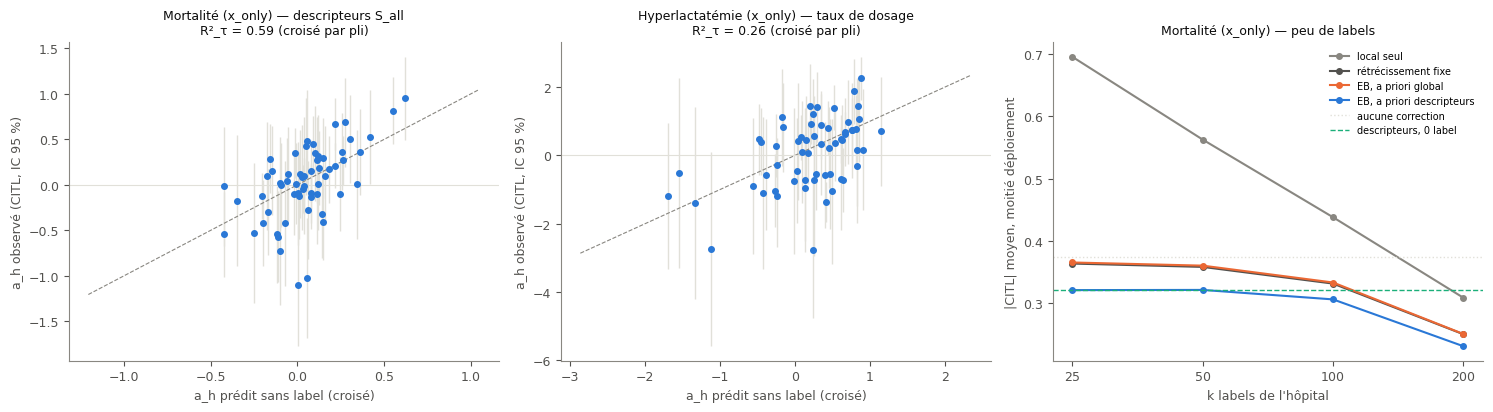

Écrit : ..\results\06b_faisabilite_opcal\rapport_06b.md | criteres_06b.csv | regime0.csv | mecanisme.csv | regimes.csv | figures/faisabilite_opcal.png


In [20]:
# ============================================================
# ÉTAPE 9 — FIGURES ET RAPPORT
# ============================================================
import matplotlib
import matplotlib.pyplot as plt
PAL = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": PAL["muted"],
                     "axes.labelcolor": PAL["ink2"], "xtick.color": PAL["ink2"], "ytick.color": PAL["ink2"], "font.size": 9})

panels = [(PRIMARY, "S_all", "Mortalité (x_only) — descripteurs S_all")]
if MECH_TASK in CAL:
    panels.append((MECH_TASK, "S_mech", "Hyperlactatémie (x_only) — taux de dosage"))
fig, axes = plt.subplots(1, len(panels) + 1, figsize=(5 * (len(panels) + 1), 4.2))
for ax, (t, s, title) in zip(axes, panels):
    cal, pr = CAL[t], PRIORS[(t, s)]
    se = np.sqrt(cal["var_citl"])
    ax.errorbar(pr["a_hat"], cal["citl"], yerr=1.96 * se, fmt="o", ms=4, color=PAL["s1"], ecolor=PAL["grid"], elinewidth=1)
    lim = [min(cal["citl"].min(), pr["a_hat"].min()) - 0.1, max(cal["citl"].max(), pr["a_hat"].max()) + 0.1]
    ax.plot(lim, lim, color=PAL["muted"], lw=0.8, ls="--")
    ax.axhline(0, color=PAL["grid"], lw=0.8)
    r2 = TAB_R0.loc[(t, s), "R2_tau"]
    ax.set_title(f"{title}\nR²_τ = {r2:.2f} (croisé par pli)", fontsize=9, color=PAL["ink"])
    ax.set_xlabel("a_h prédit sans label (croisé)")
    ax.set_ylabel("a_h observé (CITL, IC 95 %)")
ax = axes[-1]
wide = TAB_SIM[PRIMARY].pivot(index="k", columns="method", values="abs_citl")
ks = [k_ for k_ in K_GRID if k_ in wide.index]
for mth, col, lab in [("local", PAL["muted"], "local seul"), ("retrecissement_fixe", PAL["ink2"], "rétrécissement fixe"),
                      ("EB_global", PAL["s2"], "EB, a priori global"), ("EB_descripteurs", PAL["s1"], "EB, a priori descripteurs")]:
    ax.plot(ks, wide.loc[ks, mth], marker="o", ms=4, color=col, label=lab)
ax.axhline(wide.loc[0, "aucune"], color=PAL["grid"], lw=1, ls=":", label="aucune correction")
ax.axhline(wide.loc[0, "descripteurs"], color=PAL["s3"], lw=1, ls="--", label="descripteurs, 0 label")
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_xlabel("k labels de l'hôpital"); ax.set_ylabel("|CITL| moyen, moitié déploiement")
ax.set_title("Mortalité (x_only) — peu de labels", fontsize=9, color=PAL["ink"])
ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "faisabilite_opcal.png", dpi=200); plt.show()

def md_table(df, digits=3):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    esc = lambda x: str(x).replace("|", "\\|")
    head = "| " + " | ".join([esc(df.index.name or "")] + [esc(c) for c in df.columns]) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " | ".join([esc(i)] + [esc(v) for v in row]) + " |" for i, row in zip(df.index, df.to_numpy())]
    return "\n".join([head, sep] + body)

r0 = TAB_R0.reset_index()
r0["ligne"] = r0["tâche"] + " / " + r0["ensemble"]
r0 = r0.set_index("ligne")[["descripteurs", "mean_abs_citl", "R2_tau", "R2_tau_IC_bas", "R2_tau_IC_haut", "gain_vs_E1", "gain_IC_bas", "gain_IC_haut"]]
sims = "\n\n".join(f"**{t}** (a priori {SIM_SPECS[t]})\n\n" + md_table(TAB_SIM[t].pivot(index="method", columns="k", values="abs_citl").rename_axis("méthode \\ k"))
                   for t in TAB_SIM)
rapport = f"""# Rapport 06b — faisabilité de la calibration de site sans label (OP-Cal)

Généré le {datetime.now():%Y-%m-%d %H:%M} par `notebooks/06b_faisabilite_opcal.ipynb`. Protocole `{protocol['hash']}`. Agrégats uniquement.

## Verdict : {VERDICT}

{md_table(CRITERES.set_index('code'))}

## Calibration de transfert (hôpitaux tenus à l'écart)

{md_table(TAB_CAL)}

## Régime 0 — prédiction croisée de a_h

{md_table(r0)}

## Mécanisme (labels définis par un examen)

{md_table(TAB_MECH) if len(TAB_MECH) else 'non disponible'}

Lactate, split train, par tiers de dosage :

{md_table(TAB_TERC, 4)}

## Régimes 1 et 2 — |CITL| moyen sur la moitié déploiement

k = 0 : sans label ; k = −1 : nombre d'événements (régime 1).

{sims}

## Contrôles

{md_table(CONTROLES.set_index('controle'))}
"""
(RES_DIR / "rapport_06b.md").write_text(rapport, encoding="utf-8")
print(f"Écrit : {RES_DIR / 'rapport_06b.md'} | criteres_06b.csv | regime0.csv | mecanisme.csv | regimes.csv | figures/faisabilite_opcal.png")